# Developer Pay-Tier Classification: Traditional ML vs Deep Learning

**Mission.** Reduce youth unemployment and underpayment in Rwanda by giving young people evidence about which skills and choices go with better pay in software careers.

**Problem statement.** Given a developer's profile (experience, education, skills, role, how they learned to code, work setup), can we predict their **compensation tier relative to peers in their country** (`Low` / `Mid` / `High`), and which factors separate the low-pay from the high-pay tier?

**Dataset.** Stack Overflow Annual Developer Survey 2023, 2024 and 2025 (open CSVs from the `StackExchange/Survey` GitHub repository), pooled: **203,812 raw rows**.

| Link | URL |
|---|---|
| GitHub repository | _add link_ |
| Google Drive (raw data zip + best models) | _add link_ |
| Demo video | _add link_ |

**How to run.** Create the environment (`python -m venv .venv`, then `pip install -r requirements.txt`), open this notebook from the `notebooks/` folder and choose **Restart → Run All**. The first run downloads the raw CSVs into `data/` (not committed to git). All logic lives in `src/`; this notebook only orchestrates and explains.

**Reproducibility.** Every random step uses `seed = 42`. Each experiment is saved by `ExperimentTracker` (model file, settings JSON, one row in `results/experiments.csv`, TensorBoard scalars in `logs/`). A rerun with unchanged code, data and settings **reloads** the saved model instead of refitting, and the last section refits on purpose to prove the numbers come out the same.

## 2. Setup

**Purpose.** Make `src/` importable, turn on auto-reload (edits in `src/` are picked up without restarting), fix the random seeds and print the library versions used for the results.

**What to look for.** The versions printed here are the ones also stored in every `results/settings/exp_*.json`.

In [1]:
import sys
sys.path.append("..")

%load_ext autoreload
%autoreload 2

import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.experiments import set_seeds, library_versions

SEED = 42
set_seeds(SEED)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 160)
warnings.filterwarnings("ignore", category=FutureWarning)
FIG = "../figures"
library_versions()

{'python': '3.14.7',
 'numpy': '2.5.4',
 'pandas': '3.0.6',
 'scikit-learn': '1.9.1',
 'tensorflow': '2.22.0-rc0'}

## 3. Data loading and size check

**Purpose.** Download (first run only) and load the three survey years, then count raw rows, rows with a salary, and Rwanda rows.

**Method.** `load_years()` reads `data/survey_{year}.csv` (with `low_memory=False` so pandas reads each column with one consistent type). `harmonize()` keeps only the columns that exist in **all three** years and adds a `Year` column, so the years can be stacked into one table.

**Expected output.** About 203,812 raw rows. That is well above the 20,000-row requirement.

In [2]:
from src.data_loading import load_years, harmonize

frames = load_years()
for y, d in frames.items():
    print(y, d.shape,
          "| with salary:", d["ConvertedCompYearly"].notna().sum(),
          "| Rwanda rows:", (d["Country"] == "Rwanda").sum())
print("Raw rows (all years):", sum(len(d) for d in frames.values()))

df = harmonize(frames)
print("\nPooled table:", df.shape, "-> shared columns (excluding Year):", df.shape[1] - 1)

2023 (89184, 84) | with salary: 48019 | Rwanda rows: 27
2024 (65437, 114) | with salary: 23435 | Rwanda rows: 22
2025 (49191, 172) | with salary: 23947 | Rwanda rows: 15
Raw rows (all years): 203812

Pooled table: (203812, 38) -> shared columns (excluding Year): 37


**Interpretation.** The three years give **203,812 raw rows** (2023: 89,184; 2024: 65,437; 2025: 49,191). Only **37 columns are shared** by all three years, because each year asked a different set of questions (2025 alone has 172 columns). Rwanda has only 64 raw rows (27 + 22 + 15), far too few to model, so Rwanda is used as a descriptive case study, not as a modelling target.

## 4. Exploration

**Purpose.** Understand who answered the salary question, how much is missing per survey year, and what the salary distribution looks like. This tells us which filters and which features are safe to use.

**Method.** We look only at respondents who reported a salary (the rows that can get a label). We print (1) the `MainBranch` and `Employment` mix, (2) the share of missing values per column per year, and (3) salary percentiles. We also plot salary on a log scale, because salaries span three orders of magnitude.

In [3]:
lab = df[df["ConvertedCompYearly"].notna()].copy()
print("Labelled rows:", len(lab))
print(lab["MainBranch"].value_counts(), "\n")
print(lab["Employment"].value_counts().head(8))

Labelled rows: 95401
MainBranch
I am a developer by profession                                                                86098
I am not primarily a developer, but I write code sometimes as part of my work/studies          7738
I used to be a developer by profession, but no longer am                                        498
I work with developers or my work supports developers but am not a developer by profession      390
I am learning to code                                                                           363
I code primarily as a hobby                                                                     314
Name: count, dtype: int64 

Employment
Employed, full-time                                                         56887
Employed                                                                    19500
Independent contractor, freelancer, or self-employed                         8580
Employed, full-time;Independent contractor, freelancer, or self-employed     4983
E

In [4]:
# Share missing per column and year (labelled rows only), worst columns first
feature_cols = [c for c in df.columns
                if c not in ["ResponseId", "CompTotal", "Currency", "ConvertedCompYearly", "Year"]]
miss = lab.groupby("Year")[feature_cols].apply(lambda g: g.isna().mean()).T.round(2)
miss.sort_values(2025, ascending=False).head(20)

Year,2023,2024,2025
WebframeWantToWorkWith,0.32,0.31,0.46
PlatformWantToWorkWith,0.37,0.37,0.40
DatabaseWantToWorkWith,0.27,0.24,0.40
OfficeStackAsyncWantToWorkWith,0.32,0.27,0.31
WebframeHaveWorkedWith,0.21,0.21,0.31
LearnCode,0.00,0.00,0.29
PlatformHaveWorkedWith,0.22,0.24,0.25
DatabaseHaveWorkedWith,0.13,0.13,0.23
LanguageWantToWorkWith,0.07,0.06,0.21
OpSysProfessional use,0.06,0.06,0.13


count       95401.0
mean        98607.0
std        543922.0
min             1.0
1%            174.0
5%           4365.0
25%         40061.0
50%         72821.0
75%        119631.0
95%        225000.0
99%        400000.0
max      74351432.0
Name: ConvertedCompYearly, dtype: float64


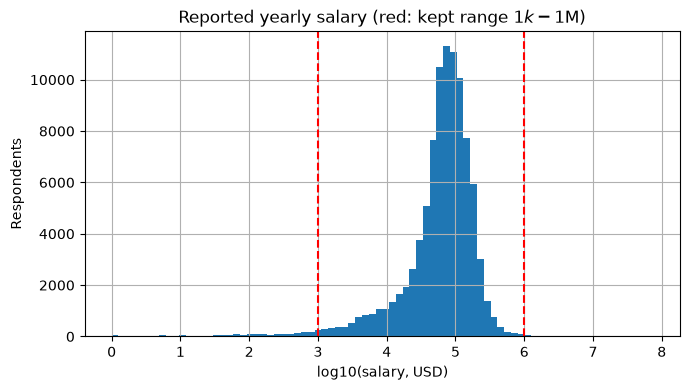

In [5]:
print(lab["ConvertedCompYearly"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(0))

fig, ax = plt.subplots(figsize=(7, 4))
np.log10(lab["ConvertedCompYearly"].clip(lower=1)).hist(bins=80, ax=ax)
for v in (1_000, 1_000_000):
    ax.axvline(np.log10(v), color="red", ls="--")
ax.set(xlabel="log10(salary, USD)", ylabel="Respondents",
       title="Reported yearly salary (red: kept range $1k-$1M)")
plt.tight_layout(); plt.savefig(f"{FIG}/salary_distribution.png", dpi=200); plt.show()

**Interpretation.** - **95,401** respondents reported a salary. **86,098 (90%)** of them are professional developers, so keeping only that group loses little data and makes people comparable.
- Some missingness is **by survey design**, not by respondent choice: `LearnCode` is complete in 2023/24 but 29% missing in 2025; `ICorPM` is 31-32% missing in 2023/24 but only 13% in 2025. A model could learn "missing" as a proxy for the survey year, which we must watch for.
- The `...WantToWorkWith` columns are 24-46% missing and describe wishes, not experience, so they are not used.
- Salary is extremely skewed: median **$72,821**, but the minimum is $1 and the maximum $74.4M, and 1% of rows report under $174 a year. These are almost certainly entry errors, which is why we keep $1,000-$1,000,000.

## 5. Cleaning and target construction

**Purpose.** Keep a comparable population and build the target `PayTier`.

**Method (`clean_and_label`).**
1. Keep respondents with a salary.
2. Keep professional developers (`MainBranch == "I am a developer by profession"`).
3. Keep full-time employees. In 2023/24 the answer is "Employed, full-time"; in 2025 the survey only says "Employed", so both are accepted.
4. Keep salaries between \$1,000 and \$1,000,000 to remove obvious typos (e.g. a monthly figure entered as yearly).
5. Keep countries with at least 100 rows, so a country's tercile cut-offs are not based on a handful of people.
6. **Label:** within each country, rank salaries and cut them into thirds: `Low`, `Mid`, `High`. The tiers are **relative to the country**, so a developer in Rwanda and one in the USA are each compared with their own market, not converted to one global scale.

**Why terciles?** Equal-sized classes make accuracy easy to read (chance = 33%) and avoid class imbalance. **Known risk:** the target is made by binning a numeric salary; this must be justified in the report and confirmed with the instructor.

**Expected output.** A funnel table (goes in the report), tier balance overall and by year, and how many African rows survive.

In [6]:
from src.preprocessing import clean_and_label

data, funnel = clean_and_label(df)
funnel["Dropped"] = funnel["Rows"].shift(1) - funnel["Rows"]
print(funnel.to_string(index=False), "\n")
print("Countries kept:", data["Country"].nunique())
print("\nTier balance:\n", data["PayTier"].value_counts(normalize=True).round(3))
print("\nTier balance by year:\n", pd.crosstab(data["Year"], data["PayTier"], normalize="index").round(3))

AFRICA = ["Rwanda", "Kenya", "Nigeria", "Uganda", "Ghana", "South Africa", "Ethiopia", "Tanzania"]
print("\nAfrican countries kept:\n", data[data["Country"].isin(AFRICA)].groupby("Country").size())

                        Step   Rows  Dropped
             Raw pooled rows 203812      NaN
     Respondents with salary  95401 108411.0
         Selected MainBranch  86098   9303.0
          Employed full-time  75357  10741.0
Salary in [1,000, 1,000,000]  74014   1343.0
   Countries with >=100 rows  71612   2402.0 

Countries kept: 63

Tier balance:
 PayTier
High    0.334
Mid     0.333
Low     0.333
Name: proportion, dtype: float64

Tier balance by year:
 PayTier    Low    Mid   High
Year                        
2023     0.342  0.342  0.316
2024     0.356  0.328  0.316
2025     0.285  0.319  0.395

African countries kept:
 Country
Nigeria         142
South Africa    533
dtype: int64


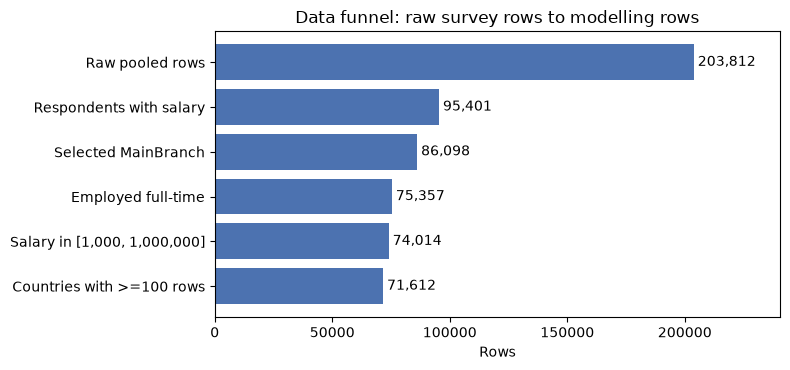

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.barh(funnel["Step"][::-1], funnel["Rows"][::-1], color="#4C72B0")
for i, v in enumerate(funnel["Rows"][::-1]):
    ax.text(v, i, f" {v:,}", va="center")
ax.set(xlabel="Rows", title="Data funnel: raw survey rows to modelling rows")
ax.set_xlim(0, funnel["Rows"].max() * 1.18)
plt.tight_layout(); plt.savefig(f"{FIG}/data_funnel.png", dpi=200); plt.show()

**Interpretation.** - The funnel goes **203,812 → 95,401 → 86,098 → 75,357 → 74,014 → 71,612** rows in 63 countries. The biggest drop is the 108,411 respondents with no salary (the question is optional).
- Tiers are balanced overall (33.3-33.4% each), as terciles should be.
- **Drift by year:** 2025 has 28.5% Low and 39.5% High, against about 34/34/32 in 2023. Tiers are pooled over years, so 2025 respondents sit higher within their country. Therefore `Year` is **never a feature** (it would learn survey drift, not skills), and accuracy is reported per year.
- Of the African countries, only **South Africa (533)** and **Nigeria (142)** pass the 100-row rule.

## 6. Feature engineering and plausibility checks

**Purpose.** Turn text answers into numbers a model can use, and remove impossible values.

**Method (`add_basic_features`).**
- `Age_num`: midpoint of the age bracket (e.g. "25-34 years old" → 30). "Prefer not to say" → missing.
- `YearsCode_num`: "Less than 1 year" → 0.5, "More than 50 years" → 51. `WorkExp_num` is already numeric.
- **Plausibility check:** a value is masked to missing if it exceeds 51 years, or exceeds (oldest age in the person's bracket − earliest plausible start age: 5 for coding, 14 for work). The raw data contained values up to 100.
- `EdLevel_ord`: education as an ordered number 1–7 (primary → professional degree). "Something else" → missing.
- `WorkExp_missing`: 1 if work experience is unknown (computed **after** masking).
- `IsYouth`: under 25. Used only to **evaluate** the model on young people, not as a model input.

**Why no leakage?** These are fixed rules written by hand; nothing is learned from the data, so applying them before the split cannot leak information from validation/test into training.

In [8]:
from src.features import add_basic_features

data = add_basic_features(data)
print("Implausible year values masked:", data.attrs["n_implausible_years"])

num_cols = ["Age_num", "YearsCode_num", "WorkExp_num", "EdLevel_ord"]
print(data[num_cols].describe().round(1), "\n")
print("Missing after masking:\n", data[num_cols].isna().sum(), "\n")
print("Youth rows (under 25):", int(data["IsYouth"].sum()))

Implausible year values masked: 113
       Age_num  YearsCode_num  WorkExp_num  EdLevel_ord
count  71579.0        71439.0      56101.0      70939.0
mean      35.2           15.8         11.7          5.0
std        9.5            9.7          8.8          1.2
min       17.0            0.5          0.0          1.0
25%       30.0            9.0          5.0          5.0
50%       30.0           13.0         10.0          5.0
75%       40.0           20.0         16.0          6.0
max       67.0           51.0         50.0          7.0 

Missing after masking:
 Age_num             33
YearsCode_num      173
WorkExp_num      15511
EdLevel_ord        673
dtype: int64 

Youth rows (under 25): 7689


In [9]:
# Education answers by year: the 2025 survey dropped "Something else"
pd.crosstab(data["EdLevel"].fillna("(blank)"), data["Year"])

Year,2023,2024,2025
EdLevel,,,
(blank),0,0,10
"Associate degree (A.A., A.S., etc.)",1282,577,531
"Bachelor’s degree (B.A., B.S., B.Eng., etc.)",18572,8234,7526
"Master’s degree (M.A., M.S., M.Eng., MBA, etc.)",10124,5211,4724
Other (please specify):,0,0,125
Primary/elementary school,136,78,55
"Professional degree (JD, MD, Ph.D, Ed.D, etc.)",1444,705,721
"Secondary school (e.g. American high school, German Realschule or Gymnasium, etc.)",1627,778,650
Some college/university study without earning a degree,4292,1980,1692


**Interpretation.** - **113** impossible experience values were masked. After masking, the maxima are 51 coding years and 50 working years.
- `WorkExp_num` is missing for 15,511 rows (22%). This is almost entirely 2023/24 (28% and 27% missing) against 0.9% in 2025, so `WorkExp_missing` partly encodes the year. `YearsCode_num` (only 173 missing) is the more reliable experience signal.
- 7,689 rows (10.7%) are youth (under 25).
- The crosstab shows "Something else" exists only in 2023/24 and "Other (please specify):" only in 2025. Both map to missing, so `EdLevel_ord` means the same thing in every year.

## 7. Train / validation / test split

**Purpose.** Hold out data the models never learn from.

**Method (`make_splits`).** 70% train, 15% validation, 15% test, **stratified on Year + PayTier** so every split has the same mix of years and tiers. All tuning uses the training set (cross-validation) or the validation set. The **test set is used once**, at the very end, for the final chosen models.

In [10]:
from src.splits import make_splits
from src.pipeline import TARGET

train, val, test = make_splits(data, seed=SEED)
print("Sizes:", {n: len(p) for n, p in [("train", train), ("val", val), ("test", test)]})
pd.DataFrame({n: p[TARGET].value_counts(normalize=True).round(3)
              for n, p in [("train", train), ("val", val), ("test", test)]})

Sizes: {'train': 50128, 'val': 10742, 'test': 10742}


,train,val,test
PayTier,,,
High,0.334,0.334,0.334
Mid,0.333,0.333,0.333
Low,0.333,0.333,0.333


**Interpretation.** Train 50,128 / validation 10,742 / test 10,742 rows, with identical tier shares (33.3-33.4%) in each split. Chance accuracy is therefore about 33%, and the majority-class baseline in experiment 0 should land there.

## 8. Preprocessing pipeline check

**Purpose.** Confirm what the models actually see.

**Method (`build_preprocessor`, a scikit-learn `ColumnTransformer`).**
- **Numeric** (`Age_num`, `YearsCode_num`, `EdLevel_ord`, `WorkExp_num`, `WorkExp_missing`): fill missing with the training median, then standardise.
- **Multi-select skills** (`LanguageHaveWorkedWith`, `DatabaseHaveWorkedWith`, `PlatformHaveWorkedWith`, `WebframeHaveWorkedWith`, `DevType`, `LearnCode`): `MultiHotEncoder` creates one 0/1 column per answer that appears in at least 1% of **training** rows. Rare answers are dropped; answers never seen in training are ignored.
- **Optional categoricals** (job context: `OrgSize`, `RemoteWork`, `ICorPM`, `Industry`; or `Country`): fill with "Unknown", one-hot encode.
- **Everything else is dropped** (`remainder="drop"`), including salary, currency, `Year` and `ResponseId`, so the label cannot leak into the features.

Because the preprocessor sits **inside** each model `Pipeline`, it is re-fitted on the training rows (or on each training fold during cross-validation), which prevents leakage.

In [11]:
from src.pipeline import build_preprocessor, MULTI

pre = build_preprocessor().fit(train)
names = pre.get_feature_names_out()
enc = pre.named_transformers_["multi"]
print("Answers kept per multi-select column:", {c: len(v) for c, v in enc.vocab_.items()})
print("Total features:", len(names), "(5 numeric +", len(enc.feature_names_), "multi-hot)")
print("Example feature names:", list(names[:3]) + list(names[5:8]))

Answers kept per multi-select column: {'LanguageHaveWorkedWith': 36, 'DatabaseHaveWorkedWith': 26, 'PlatformHaveWorkedWith': 43, 'WebframeHaveWorkedWith': 29, 'DevType': 16, 'LearnCode': 20}
Total features: 175 (5 numeric + 170 multi-hot)
Example feature names: ['num__Age_num', 'num__YearsCode_num', 'num__EdLevel_ord', 'multi__LanguageHaveWorkedWith=Assembly', 'multi__LanguageHaveWorkedWith=Bash/Shell (all shells)', 'multi__LanguageHaveWorkedWith=C']


**Interpretation.** The core feature matrix has **175 columns**: 5 numeric plus 170 multi-hot answers (36 languages, 26 databases, 43 platforms, 29 web frameworks, 16 developer roles, 20 ways of learning to code). These are the inputs for experiments 0-5; later experiments add or remove groups to test what matters.